# Lesson 6.2: p-values and Significance

Turn the bottling plant's z statistic into one-sided and two-sided p-values, and see what alpha = 0.05 means as a cut-off.

Part of *Statistics from Scratch*. Run each cell with **Shift + Enter**, top to bottom.

## The question

A bottling plant claims its bottles hold 500 mL on average, and the filling machine's spread is known (sigma = 12 mL). A quality inspector weighs 64 bottles and gets a mean of 503.6 mL. Is the plant really overfilling, or could a gap of 3.6 mL just be sampling noise?

If a package is missing on your computer, run the next cell once. In Google Colab everything is already installed.

In [ ]:
%pip install -q numpy scipy pandas statsmodels matplotlib

## Step 1: From the data to a z statistic

H0: the true mean fill is 500 mL. H1: it is not 500 mL (over or under). We weighed 64 bottles (sigma = 12 mL known) and got 503.6 mL. The z statistic says how many standard errors the sample mean sits from the claim.

In [1]:
import numpy as np  # Load NumPy for the square root and number work, under the short name np.
from scipy import stats  # Load SciPy's statistics tools; stats.norm is the normal curve we need for p-values.

mu0, sigma, n, xbar = 500, 12, 64, 503.6  # Store the claim (500), the known sigma (12), the sample size (64) and the sample mean (503.6) in one line so every later line can use them.

se = sigma / np.sqrt(n)  # The standard error: how much a mean of 64 bottles typically wobbles. We divide sigma by the square root of n.
z = (xbar - mu0) / se  # The z statistic: the gap between our mean and the claim, measured in standard errors. Dividing by the SE makes it comparable to the normal curve.

print(f'standard error = {se:.2f}')  # Print the standard error rounded to 2 decimals so we can check it by hand (12 / 8 = 1.5).
print(f'z = {z:.2f}')  # Print z, the distance from the claim in standard errors.

standard error = 1.50
z = 2.40


**What this means.** The standard error is 1.50 mL, so a mean of 64 bottles typically wobbles about 1.5 mL from the true mean. Our sample mean is z = 2.40 standard errors above the claim. That is a fairly large gap, but z alone is not yet a probability, so next we turn it into a p-value.

## Step 2: One-sided and two-sided p-values

norm.sf (the 'survival function') gives the area in the right tail beyond z. The two-sided p-value counts both tails, so it is double the one-sided value. A left tail uses norm.cdf.

In [2]:
p_right = stats.norm.sf(z)         # area beyond +z  # norm.sf (survival function) gives the area of the normal curve beyond z on the right. That is the p-value if H1 says 'more than 500'.
p_left = stats.norm.cdf(z)         # area below z  # norm.cdf gives the area below z on the left. That is the p-value if H1 says 'less than 500'.
p_two = 2 * stats.norm.sf(abs(z))  # both tails  # For H1 'not equal to 500' both tails count, so we double the area beyond |z|. abs() makes it work for a negative z too.

print(f'right-tailed p = {p_right:.4f}')  # Print the right-tailed p-value to 4 decimals.
print(f'left-tailed p  = {p_left:.4f}')  # Print the left-tailed p-value to 4 decimals.
print(f'two-tailed p   = {p_two:.4f}')  # Print the two-tailed p-value, the one that matches our H1 of 'different'.

right-tailed p = 0.0082
left-tailed p  = 0.9918
two-tailed p   = 0.0164


**What this means.** The two-tailed p is 0.0164. If the true mean were 500 mL, a sample mean at least 2.4 standard errors away in either direction would happen about 1.6% of the time. The right-tailed p (0.0082) is exactly half. The left-tailed p of 0.9918 shows the data point away from 'below 500'. None of these is the chance that the claim is true.

## Step 3: Alpha as a cut-off (critical values)

Alpha = 0.05 is the surprise threshold. norm.ppf turns it into critical z values that cut off the rejection region. Comparing |z| with the critical value gives the same decision as comparing p with alpha.

In [3]:
alpha = 0.05  # Choose the surprise threshold alpha = 0.05 before judging the data, so we cannot move the goal posts.
crit_two = stats.norm.ppf(1 - alpha / 2)   # two-tailed cut-off  # norm.ppf is the inverse of the curve: the z value that leaves alpha/2 in each tail. This gives the two-tailed cut-off.
crit_right = stats.norm.ppf(1 - alpha)     # right-tailed cut-off  # For a one-sided test all of alpha sits in one tail, so the right-tailed cut-off is the z with 5% above it.

print(f'two-tailed critical z = +/-{crit_two:.3f}')  # Print the two-tailed critical value; any z beyond plus or minus this is in the rejection region.
print(f'right-tailed critical z = {crit_right:.3f}')  # Print the right-tailed critical value.
print('p <= alpha?     ', p_two <= alpha)  # Rule 1: reject H0 when the p-value is at or below alpha. This prints True or False.
print('|z| > critical?', abs(z) > crit_two)  # Rule 2: reject H0 when |z| is beyond the critical value. It must agree with rule 1.

two-tailed critical z = +/-1.960
right-tailed critical z = 1.645
p <= alpha?      True
|z| > critical? True


**What this means.** The two-tailed critical value is 1.960 (and 1.645 for a right-tailed test). Our |z| of 2.40 is beyond 1.96, and p = 0.0164 is below 0.05, so both rules print True and both say reject H0. The two rules always agree, so use whichever is handier.

## Step 4: Draw the tail areas

A picture of the p-value: the red areas are the two tails beyond +z and -z. Their combined area is the two-sided p-value, and they are tiny compared with the whole curve.

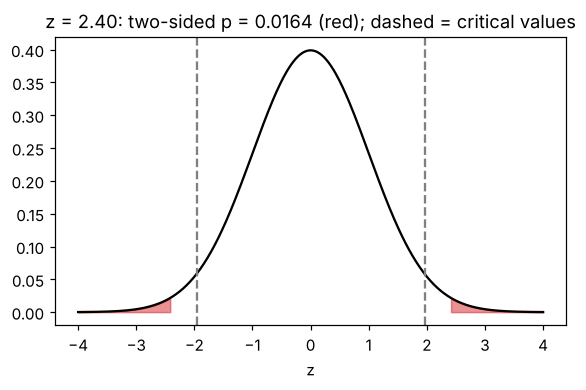

In [4]:
import matplotlib.pyplot as plt  # Load matplotlib's plotting tools as plt. We keep this import here because only this step draws.

x = np.linspace(-4, 4, 400)  # Make 400 evenly spaced z values from -4 to 4 to draw the curve smoothly.
plt.figure(figsize=(6, 3.4))  # Start a new, small figure (6 by 3.4 inches) so it fits on the page.
plt.plot(x, stats.norm.pdf(x), color='black')  # Draw the normal curve in black: its height at each z is stats.norm.pdf.
for side in (x >= abs(z), x <= -abs(z)):  # Loop over the two tail regions: z at or above +|z|, and at or below -|z|.
    plt.fill_between(x[side], stats.norm.pdf(x[side]), color='tab:red', alpha=0.5)  # Shade each tail in red. The shaded area is the probability of being that extreme, so it is the p-value.
plt.axvline(crit_two, linestyle='--', color='gray')  # Draw a dashed line at the upper critical value, where the rejection region begins.
plt.axvline(-crit_two, linestyle='--', color='gray')  # Draw the matching dashed line at the lower critical value.
plt.title(f'z = {z:.2f}: two-sided p = {p_two:.4f} (red); dashed = critical values')  # Title the plot with the numbers so the picture explains itself.
plt.xlabel('z')  # Label the horizontal axis; z is measured in standard errors.
plt.show()  # Show the figure.

**What this means.** The red tails beyond +2.40 and -2.40 together are the two-sided p of 0.0164, a very small share of the curve. Our z lies outside the dashed critical lines at +/-1.96, so it is in the rejection region. The picture shows p is an area, the share of outcomes this extreme, and not the probability that H0 is true.

## So, what is the answer?

The z statistic of 2.40 gives a two-sided p-value of 0.0164, below 0.05, so there is evidence that the mean fill differs from 500 mL, and the sample mean of 503.6 mL points to overfilling. Caution: the p-value does not say how big the problem is. A 3.6 mL gap is under 1% of a bottle, and whether it matters is a business decision.

## Now you try

A phone maker rates its battery at 12 hours of video playback. Engineers know from years of testing that the spread is sigma = 0.8 hours. A reviewer tests 25 phones and records the hours each lasts. Do the phones last LESS than the rated 12 hours on average? Use a one-sided z-test.

**Data:** hours = [11.6, 11.8, 11.4, 10.9, 11.2, 10.8, 11.6, 12.7, 11.2, 11.1, 12.0, 11.9, 11.7, 10.9, 11.6, 12.2, 10.5, 11.2, 10.1, 10.6, 10.1, 11.4, 10.6, 11.8, 11.7]

1. State H0 and H1 (which tail?) and find the sample mean.
2. Compute the standard error and the z statistic.
3. Find the left-tailed p-value and the two-tailed p-value.
4. Compare z with the critical value for alpha = 0.05 and state the decision.

*Hint:* This is the bottling lab with a left tail. Use norm.cdf(z) for the left-tailed p and norm.ppf(0.05) for the critical value.

In [ ]:
# Your turn: write your code here


### Solution (try first, then peek)

In [ ]:
import numpy as np
from scipy import stats

hours = [11.6, 11.8, 11.4, 10.9, 11.2, 10.8, 11.6, 12.7, 11.2, 11.1, 12.0, 11.9, 11.7, 10.9, 11.6, 12.2, 10.5, 11.2, 10.1, 10.6, 10.1, 11.4, 10.6, 11.8, 11.7]
mu0, sigma = 12, 0.8
xbar, n = np.mean(hours), len(hours)
z = (xbar - mu0) / (sigma / np.sqrt(n))
print(f'mean = {xbar:.3f}, z = {z:.3f}')
print(f'left-tailed p = {stats.norm.cdf(z):.1e}')
print(f'two-tailed p  = {2 * stats.norm.sf(abs(z)):.1e}')
print(f'critical z (left, alpha 0.05) = {stats.norm.ppf(0.05):.3f}')
print('reject H0?', z < stats.norm.ppf(0.05))

mean = 11.304, z = -4.350
left-tailed p = 6.8e-06
two-tailed p  = 1.4e-05
critical z (left, alpha 0.05) = -1.645
reject H0? True


**Answer.** The mean is 11.304 hours and z = -4.350. The left-tailed p is about 6.8e-06 (roughly 7 in a million), far below 0.05, and z is below the critical value -1.645, so we reject H0: the phones last less than 12 hours on average. Caution: the test assumes sigma = 0.8 is truly known, and the 0.7 hour shortfall is for you to judge, not the p-value.

## The same question in R, SPSS and Stata

**R**

```r
xbar <- 503.6; mu0 <- 500; sigma <- 12; n <- 64  # Store the sample mean, the claimed mean, the known sigma and n on one line (semicolons separate commands in R).
z <- (xbar - mu0) / (sigma / sqrt(n))  # Compute z: the gap divided by the standard error sigma / sqrt(n).
z  # Typing the name z alone prints its value.
pnorm(z, lower.tail = FALSE)   # right-tailed p  # pnorm gives the area to the left; lower.tail = FALSE flips it to the right tail, the right-tailed p-value.
pnorm(z)                       # left-tailed p  # pnorm(z) is the area to the left of z, the left-tailed p-value.
2 * pnorm(-abs(z))             # two-tailed p  # Two tails: double the area below -|z|. This is the two-tailed p-value.
qnorm(c(0.975, 0.95))          # critical values  # qnorm is the inverse of pnorm: it returns the critical z values for 0.975 (two-tailed 5%) and 0.95 (right-tailed 5%).
```

How to read it: z prints 2.4. The right-tailed p is 0.0082, the left-tailed 0.9918 and the two-tailed 0.0164. qnorm gives 1.959964 and 1.644854. For the question 'different from 500?' use 0.0164: it is below 0.05, so we reject H0.

**SPSS** (Transform > Compute Variable (use the CDF.NORMAL and IDF.NORMAL functions))

```
DATA LIST FREE / xbar mu0 sigma n.
BEGIN DATA
503.6 500 12 64
END DATA.
COMPUTE z = (xbar - mu0) / (sigma / SQRT(n)).
COMPUTE p_right = 1 - CDF.NORMAL(z, 0, 1).
COMPUTE p_left = CDF.NORMAL(z, 0, 1).
COMPUTE p_two = 2 * (1 - CDF.NORMAL(ABS(z), 0, 1)).
COMPUTE crit_two = IDF.NORMAL(0.975, 0, 1).
COMPUTE crit_right = IDF.NORMAL(0.95, 0, 1).
LIST.
```

How to read it: In the LIST output look at z (2.40, SPSS shows 2 decimals), p_right (0.01), p_left (0.99), p_two (0.02) and the critical values 1.96 and 1.64 (rounded display). The exact two-tailed p is 0.0164, below 0.05, so we reject H0.

**Stata**

```
display (503.6 - 500) / (12 / sqrt(64))
display 1 - normal(2.4)         // right-tailed p
display normal(2.4)             // left-tailed p
display 2 * (1 - normal(2.4))   // two-tailed p
display invnormal(0.975)        // two-tailed critical value
display invnormal(0.95)         // right-tailed critical value
```

How to read it: The first line shows 2.4, then the p-values .0081975 (right), .9918025 (left) and .01639 (two-tailed), and the critical values 1.959964 and 1.644854. Use the two-tailed 0.0164 for our question: below 0.05, so reject H0.